# 01 Audit and exploratory analysis
**Goal:** (1) prove the dataset is complete and leakage-safe, (2) produce the first
paper figures. Nothing here trains a model, and the test split is never used for
decisions (we only describe the data).

Run the cells top to bottom. Every figure is saved to `results/figures/`.

In [1]:
# --- Setup: make imports work whether the notebook is opened from the repo root or notebooks/
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "src")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data_loader import get_energy_data
from features import make_dataset
from splits import QUARTER_HOUR_START, add_flags

FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=200)
    plt.show()


raw = get_energy_data()                  # hourly grid, before feature building
data = add_flags(make_dataset())         # model-ready rows (incomplete rows dropped)
data["year"] = data.index.tz_convert("Europe/Berlin").year   # LOCAL calendar year
print("raw rows:", len(raw), "| model-ready rows:", len(data))

Fetching raw data from ENTSO-E API...
Standardizing resolutions to hourly mean format...

--- Initial NaN Inspection ---
Prices NaNs: 0
Load Forecast NaNs:
 Forecasted Load    50
dtype: int64
Wind/Solar Forecast NaNs:
 Solar            3
Wind Offshore    0
Wind Onshore     3
dtype: int64

Missing price hours: 0
Rows with unresolved feature NaNs: 42
Saving processed data to local cache: data\de_lu_energy_data.parquet
Loading data from local cache: data\de_lu_energy_data.parquet
Rows before drop: 67920
Missing values per column (rows that will be dropped):
load_forecast           42
neg_count_prev_day      23
price_lag_168          168
price_lag_24            31
price_prev_day_mean     23
renewable_share         42
res_share               42
residual_load           42
Rows dropped: 217 | rows kept: 67703
raw rows: 67920 | model-ready rows: 67703


## 1. Completeness: expected vs actual rows per year
The loader reindexes to a full hourly grid, so row counts should match exactly.
Years are UTC calendar years here (8760 hours, or 8784 in leap years).

In [2]:
expected = pd.Series(
    pd.date_range("2019-01-01", "2026-09-30 23:00", freq="h", tz="UTC").year
).value_counts().sort_index()
actual = raw.groupby(raw.index.year).size()
check = pd.DataFrame({"expected": expected, "actual": actual})
check["difference"] = check["actual"] - check["expected"]
print(check)
print("\nduplicate timestamps:", raw.index.duplicated().sum())
print("missing price hours:", int(raw["price"].isna().sum()))

      expected  actual  difference
2019      8760    8760           0
2020      8784    8784           0
2021      8760    8760           0
2022      8760    8760           0
2023      8760    8760           0
2024      8784    8784           0
2025      8760    8760           0
2026      6552    6552           0

duplicate timestamps: 0
missing price hours: 0


## 2. Missing values per column and year, and what got dropped
`raw` NaNs are what is left after the short forward-fill. The "dropped" table counts
rows removed when building features (the first 7 days have no weekly lag, plus gaps).

In [3]:
print("NaNs per column and year (raw, after short ffill):")
print(raw.isna().groupby(raw.index.year).sum())

dropped = raw.index.difference(data.index)
print("\nRows dropped when building features, by year:")
print(pd.Series(dropped.year).value_counts().sort_index())

NaNs per column and year (raw, after short ffill):
               price  neg_frac_target  load_forecast  solar_forecast  \
timestamp_utc                                                          
2019               0                0              0               0   
2020               0                0              0               0   
2021               0                0              0               0   
2022               0                0             42               0   
2023               0                0              0               0   
2024               0                0              0               0   
2025               0                0              0               0   
2026               0                0              0               0   

               wind_offshore_forecast  wind_onshore_forecast  
timestamp_utc                                                 
2019                                0                      0  
2020                                0  

## 3. Daylight-saving audit
In local time most days have 24 hours, spring days have 23 and autumn days have 25.
Because we stored everything in UTC, these must appear correctly and nothing may be
duplicated or lost. The first and last local days are partial (the data starts and ends
at UTC midnight), which is expected.

In [4]:
loc_days = raw.index.tz_convert("Europe/Berlin").normalize()
hours_per_day = pd.Series(1, index=loc_days).groupby(level=0).sum()
print(hours_per_day.value_counts().sort_index())
print("\nDays that are not 24 hours long:")
print(hours_per_day[hours_per_day != 24].to_string())

2        1
23       9
24    2814
25       7
Name: count, dtype: int64

Days that are not 24 hours long:
timestamp_utc
2019-01-01 00:00:00+01:00    23
2019-03-31 00:00:00+01:00    23
2019-10-27 00:00:00+02:00    25
2020-03-29 00:00:00+01:00    23
2020-10-25 00:00:00+02:00    25
2021-03-28 00:00:00+01:00    23
2021-10-31 00:00:00+02:00    25
2022-03-27 00:00:00+01:00    23
2022-10-30 00:00:00+02:00    25
2023-03-26 00:00:00+01:00    23
2023-10-29 00:00:00+02:00    25
2024-03-31 00:00:00+01:00    23
2024-10-27 00:00:00+02:00    25
2025-03-30 00:00:00+01:00    23
2025-10-26 00:00:00+02:00    25
2026-03-29 00:00:00+01:00    23
2026-10-01 00:00:00+02:00     2


## 4. The core fact: negative-price hours per year
2026 only covers January to September, so a full-year comparison would be unfair
(winter has few negative hours). The Jan-Sep column compares every year on the same months.

      hours  neg_hours  neg_rate_pct  mean_price  min_price  \
year                                                          
2019   8590      188.0          2.19       37.63     -90.01   
2020   8783      298.0          3.39       30.47     -83.94   
2021   8759      139.0          1.59       96.86     -69.00   
2022   8717       69.0          0.79      235.70     -19.04   
2023   8759      301.0          3.44       95.18    -500.00   
2024   8783      457.0          5.20       78.51    -135.45   
2025   8759      576.0          6.58       89.33    -250.32   
2026   6553      472.0          7.20      107.73    -499.00   

      neg_rate_JanSep_pct  
year                       
2019                 2.27  
2020                 3.74  
2021                 1.94  
2022                 0.61  
2023                 2.87  
2024                 6.28  
2025                 8.01  
2026                 7.21  


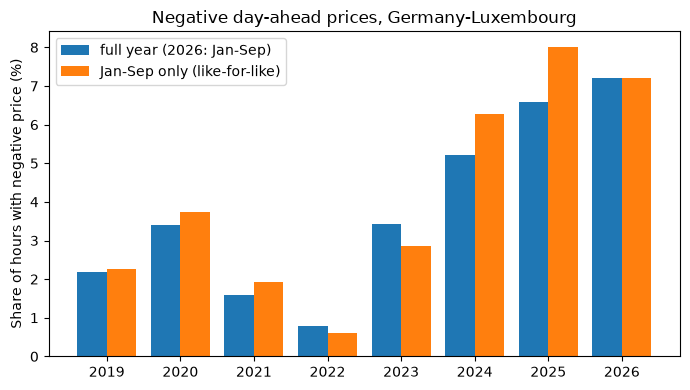

In [5]:
local = data.index.tz_convert("Europe/Berlin")
yearly = data.groupby("year").agg(
    hours=("target", "size"),
    neg_hours=("target", "sum"),
    neg_rate_pct=("target", lambda s: s.mean() * 100),
    mean_price=("price", "mean"),
    min_price=("price", "min"),
)
janjun = data[local.month <= 9].groupby("year")["target"].mean() * 100
yearly["neg_rate_JanSep_pct"] = janjun
print(yearly.round(2))
yearly.round(3).to_csv(ROOT / "results" / "negative_hours_by_year.csv")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(yearly))
ax.bar(x - 0.2, yearly["neg_rate_pct"], 0.4, label="full year (2026: Jan-Sep)")
ax.bar(x + 0.2, yearly["neg_rate_JanSep_pct"], 0.4, label="Jan-Sep only (like-for-like)")
ax.set_xticks(x, yearly.index)
ax.set_ylabel("Share of hours with negative price (%)")
ax.set_title("Negative day-ahead prices, Germany-Luxembourg")
ax.legend()
savefig(fig, "neg_rate_by_year.png")

## 5. Did the 15-minute switch (1 Oct 2025) break anything?
Before the switch each hour had one price, so `neg_frac_target` can only be 0 or 1.
After it, fractional values (0.25, 0.5, 0.75) should appear. Price and solar curves should
show no jump or gap at the red line.

neg_frac_target values BEFORE switch:
 neg_frac_target
0.0    56965
1.0     1977

neg_frac_target values AFTER switch:
 neg_frac_target
0.00    8140
0.25      63
0.50      93
0.75      57
1.00     408


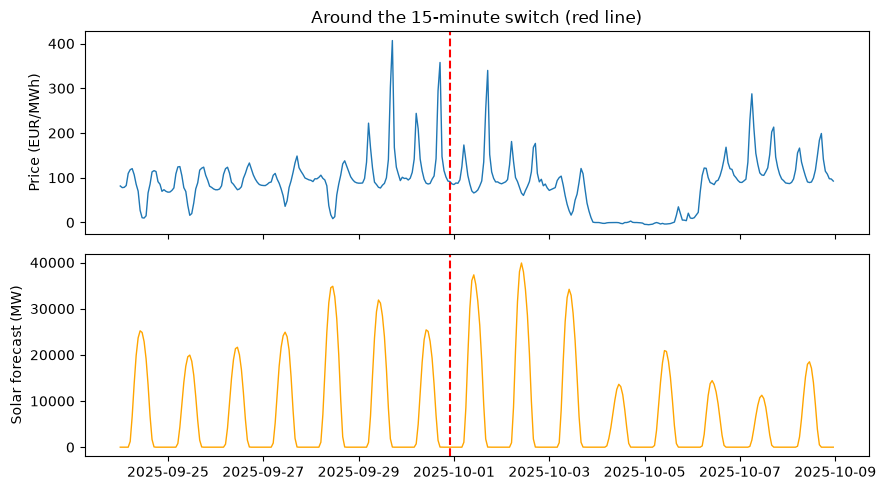

In [6]:
before = data[data.index < QUARTER_HOUR_START]["neg_frac_target"].round(2).value_counts().sort_index()
after = data[data.index >= QUARTER_HOUR_START]["neg_frac_target"].round(2).value_counts().sort_index()
print("neg_frac_target values BEFORE switch:\n", before.to_string())
print("\nneg_frac_target values AFTER switch:\n", after.to_string())

w = data.loc["2025-09-24":"2025-10-08"]
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(w.index, w["price"], lw=1)
ax[0].set_ylabel("Price (EUR/MWh)")
ax[1].plot(w.index, w["solar_forecast"], lw=1, color="orange")
ax[1].set_ylabel("Solar forecast (MW)")
for a in ax:
    a.axvline(QUARTER_HOUR_START, color="red", ls="--")
ax[0].set_title("Around the 15-minute switch (red line)")
savefig(fig, "oct2025_switch_check.png")

## 6. When do negative prices happen? (hour of day, by year)
Expect a midday peak that grows over the years: the solar signature.

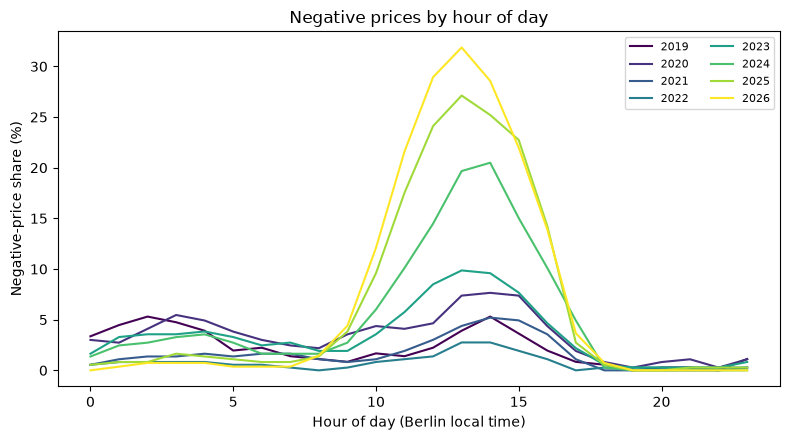

In [7]:
by_hour = data.groupby(["year", "hour"])["target"].mean().unstack(0) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = plt.cm.viridis(np.linspace(0, 1, by_hour.shape[1]))
for c, yr in zip(colors, by_hour.columns):
    ax.plot(by_hour.index, by_hour[yr], color=c, label=str(yr))
ax.set_xlabel("Hour of day (Berlin local time)")
ax.set_ylabel("Negative-price share (%)")
ax.set_title("Negative prices by hour of day")
ax.legend(ncol=2, fontsize=8)
savefig(fig, "neg_rate_by_hour.png")

## 7. Seasonality: month by year heatmap

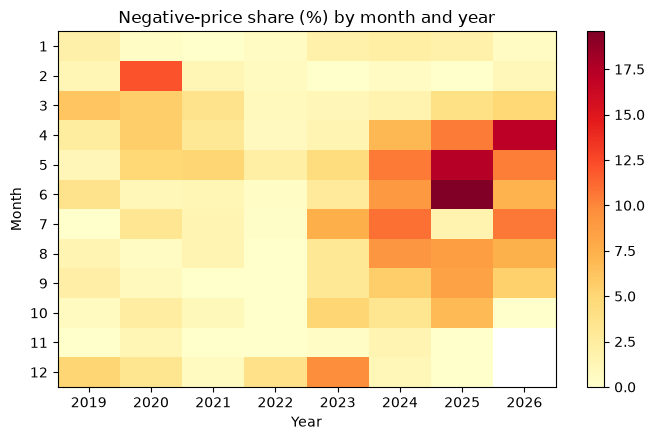

In [8]:
pivot = data.pivot_table(index="month", columns="year", values="target", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.set_xlabel("Year")
ax.set_ylabel("Month")
ax.set_title("Negative-price share (%) by month and year")
fig.colorbar(im, ax=ax)
savefig(fig, "neg_rate_month_year_heatmap.png")

## 8. Weekend and holiday effect
Low demand on weekends and holidays should push prices down. We also look at midday only
(10:00-16:00 local) where solar is strongest.

         all_hours_%  midday_10-16_%
weekday         1.61            4.07
weekend         7.98           20.33
holiday        13.42           28.78


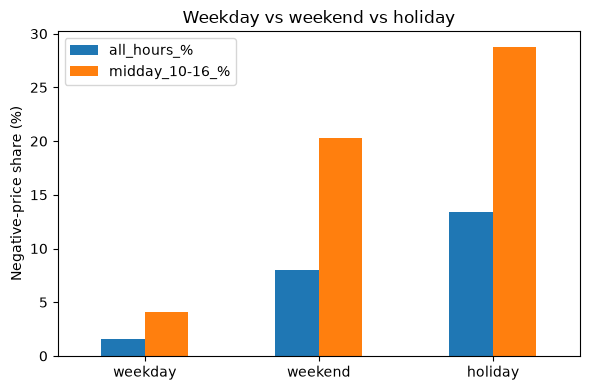

In [9]:
cat = np.where(data["is_holiday"] == 1, "holiday", np.where(data["is_weekend"] == 1, "weekend", "weekday"))
overall = data.groupby(cat)["target"].mean() * 100
midday_mask = data["hour"].between(10, 16)
midday = data[midday_mask].groupby(cat[midday_mask.to_numpy()])["target"].mean() * 100
tbl = pd.DataFrame({"all_hours_%": overall, "midday_10-16_%": midday}).loc[["weekday", "weekend", "holiday"]]
print(tbl.round(2))
ax = tbl.plot.bar(figsize=(6, 4), rot=0)
ax.set_ylabel("Negative-price share (%)")
ax.set_title("Weekday vs weekend vs holiday")
savefig(ax.figure, "neg_rate_weekend_holiday.png")

## 9. Residual load vs negative prices (motivates baseline B3 and RQ2)
Left: probability of a negative price at each residual-load level, by period. If the
curves shift right over time, the same residual load is now more likely to give negative
prices, which means a fixed threshold rule will age badly.

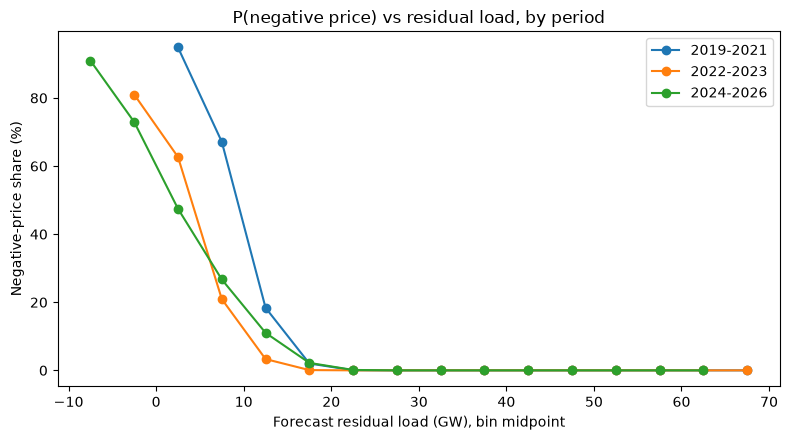

In [10]:
bins = np.arange(-10000, 75001, 5000)
data["res_bin"] = pd.cut(data["residual_load"], bins)
periods = pd.cut(data["year"], [2018, 2021, 2023, 2026], labels=["2019-2021", "2022-2023", "2024-2026"])

fig, ax = plt.subplots(figsize=(8, 4.5))
for label in periods.cat.categories:
    g = data[periods == label].groupby("res_bin", observed=True)["target"].agg(["mean", "size"])
    g = g[g["size"] >= 30]
    mid = np.array([iv.mid for iv in g.index]) / 1000
    ax.plot(mid, g["mean"] * 100, marker="o", label=label)
ax.set_xlabel("Forecast residual load (GW), bin midpoint")
ax.set_ylabel("Negative-price share (%)")
ax.set_title("P(negative price) vs residual load, by period")
ax.legend()
savefig(fig, "p_neg_vs_residual_load.png")

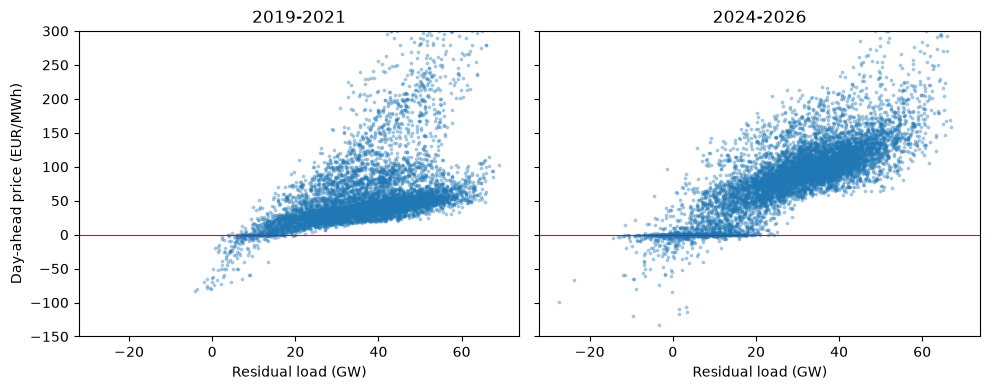

In [11]:
# Scatter of price against residual load: early vs late period (random sample for speed)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, sharex=True)
for a, (label, mask) in zip(
    axes, [("2019-2021", data["year"] <= 2021), ("2024-2026", data["year"] >= 2024)]
):
    s = data[mask].sample(min(8000, int(mask.sum())), random_state=0)
    a.scatter(s["residual_load"] / 1000, s["price"], s=3, alpha=0.3)
    a.axhline(0, color="red", lw=0.8)
    a.set_title(label)
    a.set_xlabel("Residual load (GW)")
axes[0].set_ylabel("Day-ahead price (EUR/MWh)")
axes[0].set_ylim(-150, 300)
savefig(fig, "price_vs_residual_load_scatter.png")

## 10. How deep do prices go when they are negative?
Matters for the cost angle: missing a -5 EUR hour and a -400 EUR hour are different.

count    2500.00
mean      -13.38
std        33.07
min      -500.00
25%       -12.20
50%        -2.56
75%        -0.20
max        -0.00
Name: price, dtype: float64

Share of negative hours below -50 EUR/MWh by year (%):
year
2019    11.2
2020     9.1
2021     7.2
2022     0.0
2023     5.0
2024     5.9
2025     5.2
2026     7.2
dtype: float64


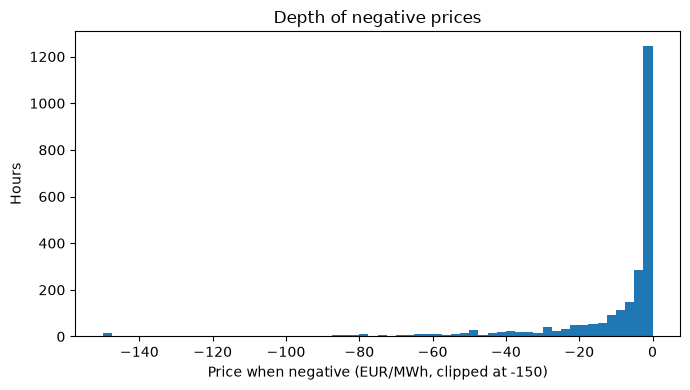

In [12]:
neg = data.loc[data["price"] < 0, "price"]
print(neg.describe().round(2))
print("\nShare of negative hours below -50 EUR/MWh by year (%):")
print((data.assign(deep=data["price"] < -50).groupby("year")["deep"].sum()
       / data.groupby("year")["target"].sum() * 100).round(1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(neg.clip(lower=-150), bins=60)
ax.set_xlabel("Price when negative (EUR/MWh, clipped at -150)")
ax.set_ylabel("Hours")
ax.set_title("Depth of negative prices")
savefig(fig, "negative_price_depth.png")

## Write these down for the paper
* Total rows, date range, number of missing hours and how they were handled (sections 1-2).
* DST handling: stored in UTC, calendar features in Europe/Berlin (section 3).
* Negative-hour rate per year (section 4). This is your motivating fact.
* The 15-minute switch and the hourly-mean target definition (section 5).
* Residual-load curve shift (section 9): your first evidence for RQ2.